In [1]:
# File Loading and Preprocessing
import pandas as pd

games = pd.read_csv("data/steam_games_clean.csv")

print(games.shape)
print(games.head())


games["tags"] = games["tags"].fillna("")

games["tag_set"] = games["tags"].apply(
    lambda tags: {tag.strip() for tag in tags.split(",") if tag.strip()}
)

# Keep games with at least one tag
games = games[games["tag_set"].map(len) > 0].copy()

print(games[["name", "tag_set"]].head())

(23500, 10)
    app_id                                   name estimated_owners  price  \
0   496350  Supipara - Chapter 1 Spring Has Come!        0 - 20000   5.24   
1  1934300                     Armored Brigade II        0 - 20000  35.99   
2  1025440                     Fantasy General II  100000 - 200000  13.99   
3   328460                                Redline        0 - 20000   1.04   
4  2403000                 Fantasy Amusement Park        0 - 20000   5.99   

   positive  negative  avg_hours  median_hours               genres  \
0       252         3   0.133333      0.133333            Adventure   
1       117        13  11.250000     20.883333  Simulation,Strategy   
2      1025       210   8.150000      0.866667             Strategy   
3        74        35   3.383333      3.383333        Action,Racing   
4         0         0   1.466667      1.600000               Casual   

                                                tags  
0                  Adventure,Visual Novel,A

In [6]:
import numpy as np
from sklearn.preprocessing import MultiLabelBinarizer

# Use a smaller sample for clustering
games = games.sample(n=1000, random_state=42).reset_index(drop=True)

# Convert game tags into binary vectors
mlb = MultiLabelBinarizer(sparse_output=True)
X = mlb.fit_transform(games["tag_set"]).astype(np.float32)

# Compute intersections
intersection = (X @ X.T).toarray()

# Count tags in each game
tag_counts = np.asarray(X.sum(axis=1)).ravel()

# Compute unions
union = tag_counts[:, None] + tag_counts[None, :] - intersection

# Jaccard similarity = intersection / union
similarity = np.divide(
    intersection,
    union,
    out=np.zeros_like(intersection),
    where=union > 0
)

# Convert similarity to distance
distances = 1 - similarity
np.fill_diagonal(distances, 0)

print("Games:", len(games))
print("Tag features:", X.shape[1])


Games: 1000
Tag features: 417


In [10]:
from sklearn.cluster import AgglomerativeClustering

np.fill_diagonal(distances, 0.0)

# Cluster games using average Jaccard distance between groups
model = AgglomerativeClustering(
    n_clusters=10,
    metric="precomputed",
    linkage="average",
)

# games must have the same row order as similarity_matrix
games = games.copy()
games["cluster"] = model.fit_predict(distances)

print("HAC cluster sizes:")
print(games["cluster"].value_counts().sort_index())


HAC cluster sizes:
cluster
0      7
1    967
2      5
3      1
4      5
5     10
6      1
7      1
8      1
9      2
Name: count, dtype: int64


In [12]:
#K-means Cluster

from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters= 10,
    random_state=42,
    n_init=10
)

games["kmeans_cluster"] = kmeans.fit_predict(X)

print("K-Means cluster sizes:")
print(games["kmeans_cluster"].value_counts().sort_index())


K-Means cluster sizes:
kmeans_cluster
0    106
1     88
2     58
3    109
4    246
5     41
6     66
7    105
8     98
9     83
Name: count, dtype: int64


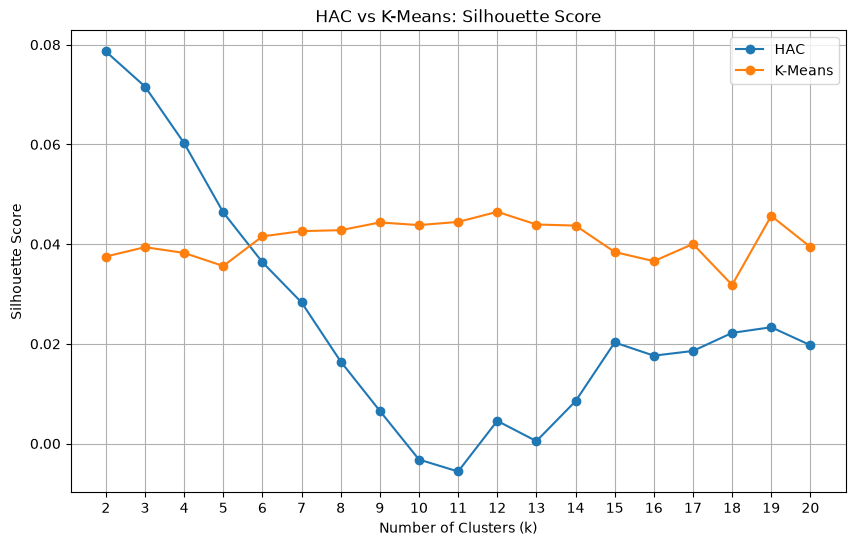

Best k for HAC: 2
Best HAC score: 0.07863370329141617
Best k for K-Means: 12
Best K-Means score: 0.04648178815841675


In [14]:


import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

k_values = range(2, 21)

hac_scores = []
kmeans_scores = []

for k in k_values:
    # HAC using Jaccard distance
    hac = AgglomerativeClustering(
        n_clusters=k,
        metric="precomputed",
        linkage="average"
    )
    hac_labels = hac.fit_predict(distances)

    # K-Means using binary tag vectors
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans_labels = kmeans.fit_predict(X)

    # Calculate silhouette scores using Jaccard distance
    hac_score = silhouette_score(
        distances, hac_labels, metric="precomputed"
    )
    kmeans_score = silhouette_score(
        distances, kmeans_labels, metric="precomputed"
    )

    hac_scores.append(hac_score)
    kmeans_scores.append(kmeans_score)

# Plot results
plt.figure(figsize=(10, 6))

plt.plot(k_values, hac_scores, marker="o", label="HAC")
plt.plot(k_values, kmeans_scores, marker="o", label="K-Means")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("HAC vs K-Means: Silhouette Score")
plt.xticks(list(k_values))
plt.legend()
plt.grid(True)
plt.show()

# Find the best k for each algorithm
best_hac_k = list(k_values)[np.argmax(hac_scores)]
best_kmeans_k = list(k_values)[np.argmax(kmeans_scores)]

print("Best k for HAC:", best_hac_k)
print("Best HAC score:", max(hac_scores))

print("Best k for K-Means:", best_kmeans_k)
print("Best K-Means score:", max(kmeans_scores))
